# Confusion Matrices: Untuned vs. Tuned Models
Follow-up to `03_baseline_model_testing.ipynb` (5 untuned models) and the five `03_2_baseline_model_tuning_*` notebooks (the same 5 models, tuned). Those notebooks report scores; this one shows **where each model's mistakes go**, with one confusion matrix per model:
- **5 untuned models**, loaded from `results/baseline/<model>/` (saved by 03)
- **5 tuned models**, loaded from `results/tuning/<model>/` (saved by each tuning notebook)

**Nothing is retrained here.** Every matrix comes from the saved **out-of-fold** probabilities: each training row was predicted by a model that never saw it (stratified 5-fold cross-validation, same folds everywhere). **The test set is still not used.**

Steps:
1. Load the saved probabilities and the shared setup
2. Turn probabilities into predictions (untuned: default rule, tuned: each fold's chosen threshold), and check they match the saved scores
3. One confusion matrix per model: 5 untuned, then 5 tuned
4. Compare untuned vs. tuned side by side

## 1. Load Results & Shared Setup
`tuning_setup.py` provides the training rows, the 5 stratified folds (the same ones every notebook used) and the prediction helpers.

`load_probabilities()` reads one model's saved out-of-fold probabilities and checks that its rows are in the **same order** as the training data (same `date` and `route_id` on every row), so each probability lines up with the right true status and fold.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score

from tuning_setup import (DISRUPTED, STATUS_ORDER, load_training_data, make_folds, predict_with_threshold)

train_df, X_train, y_train = load_training_data()
folds = make_folds(X_train, y_train)

# Which fold each training row was held out in (1 to 5)
fold_of_row = np.zeros(len(y_train), dtype=int)
for fold_number, (_, valid_index) in enumerate(folds, start=1):
    fold_of_row[valid_index] = fold_number

# Display name -> results folder name
models = {
    "Logistic Regression": "logistic_regression",
    "Random Forest": "random_forest",
    "LightGBM": "lightgbm",
    "XGBoost": "xgboost",
    "CatBoost": "catboost",
}

def load_probabilities(version, folder):
    """Saved out-of-fold probabilities for one model. version: "baseline" (untuned) or "tuning" (tuned)."""
    saved_df = pd.read_csv(f"../results/{version}/{folder}/out_of_fold_probabilities.csv")

    # Rows must line up with the training data, row for row
    same_dates = (pd.to_datetime(saved_df["date"], format="%m/%d/%Y").to_numpy() == train_df["date"].to_numpy()).all()
    same_routes = (saved_df["route_id"].to_numpy() == train_df["route_id"].to_numpy()).all()
    assert same_dates and same_routes, f"{version}/{folder}: rows are not in the training-data order"

    return saved_df[[f"prob_{status.lower()}" for status in STATUS_ORDER]].to_numpy()

untuned_probabilities = {name: load_probabilities("baseline", folder) for name, folder in models.items()}
tuned_probabilities = {name: load_probabilities("tuning", folder) for name, folder in models.items()}

print("Training rows:", len(y_train))
print("Loaded untuned:", list(untuned_probabilities))
print("Loaded tuned:  ", list(tuned_probabilities))

Training rows: 25040
Loaded untuned: ['Logistic Regression', 'Random Forest', 'LightGBM', 'XGBoost', 'CatBoost']
Loaded tuned:   ['Logistic Regression', 'Random Forest', 'LightGBM', 'XGBoost', 'CatBoost']


## 2. From Probabilities to Predictions
The saved files hold **probabilities** (one per status). A confusion matrix needs **predictions**, using the same rule each notebook reported:

| Version | Rule | Same as |
|---|---|---|
| **Untuned** | Default rule: the status with the highest probability wins | The scores in 03 |
| **Tuned** | Disrupted if its probability is at least the fold's **threshold**, otherwise the more likely of Normal and Delayed. Each fold uses the threshold chosen on the **other 4 folds** | The "tuned, own threshold" scores in each tuning notebook |

The tuned thresholds come from each model's `cv_fold_scores.csv`.

**Check:** the predictions are re-scored fold by fold and compared with the saved fold scores. If anything doesn't line up (wrong file, wrong order, wrong threshold), the check fails instead of drawing a misleading matrix.

In [2]:
def predict_tuned(name):
    """Tuned predictions: each fold uses its own threshold, chosen on the other 4 folds."""
    fold_thresholds = pd.read_csv(f"../results/tuning/{models[name]}/cv_fold_scores.csv", index_col="fold")["threshold"]
    predictions = np.zeros(len(y_train), dtype=int)
    for fold_number, threshold in fold_thresholds.items():
        rows = fold_of_row == fold_number
        predictions[rows] = predict_with_threshold(tuned_probabilities[name][rows], threshold)
    return predictions, fold_thresholds

untuned_predictions = {name: predict_with_threshold(untuned_probabilities[name]) for name in models}   # default rule
tuned_predictions, tuned_thresholds = {}, {}
for name in models:
    tuned_predictions[name], tuned_thresholds[name] = predict_tuned(name)

# Check: re-score each fold and compare with the saved fold scores
checks = []
for version, predictions in [("baseline", untuned_predictions), ("tuning", tuned_predictions)]:
    for name, folder in models.items():
        saved_f1 = pd.read_csv(f"../results/{version}/{folder}/cv_fold_scores.csv", index_col="fold")["macro_f1"]
        recomputed_f1 = pd.Series({fold: f1_score(y_train[fold_of_row == fold], predictions[name][fold_of_row == fold], average="macro")
                                   for fold in saved_f1.index})
        checks.append({"version": "untuned" if version == "baseline" else "tuned", "model": name,
                       "macro-F1 (saved)": saved_f1.mean(), "macro-F1 (recomputed)": recomputed_f1.mean(),
                       "match": np.allclose(saved_f1.to_numpy(), recomputed_f1.to_numpy())})

checks_df = pd.DataFrame(checks)
assert checks_df["match"].all(), "Recomputed scores don't match the saved scores"
checks_df.round(3)

,version,model,macro-F1 (saved),macro-F1 (recomputed),match
0,untuned,Logistic Regression,0.520,0.520,True
1,untuned,Random Forest,0.585,0.585,True
2,untuned,LightGBM,0.581,0.581,True
3,untuned,XGBoost,0.564,0.564,True
4,untuned,CatBoost,0.548,0.548,True
5,tuned,Logistic Regression,0.601,0.601,True
6,tuned,Random Forest,0.598,0.598,True
7,tuned,LightGBM,0.602,0.602,True
8,tuned,XGBoost,0.606,0.606,True
9,tuned,CatBoost,0.610,0.610,True


## 3. How to Read a Confusion Matrix
- Each **row** is the **true** status, each **column** is the **predicted** status.
- Each cell shows the **share of that true status** (rows add up to 100%) and, in brackets, the **number of rows**.
- The **diagonal** (top-left to bottom-right) is what the model got right. For the Disrupted row, the diagonal cell is **Disrupted recall**: the share of real disruptions caught.
- The **Disrupted column** shows every row the model flagged as Disrupted. Most of those are not real disruptions; the false alarms sit in the Normal and Delayed rows of that column.

Every matrix covers all 25,040 training rows (8,211 Normal, 16,030 Delayed, 799 Disrupted).

In [3]:
summary_rows = []

def show_confusion_matrix(name, version):
    """Draw one model's confusion matrix and record its key numbers for the comparison in section 6."""
    predictions = untuned_predictions[name] if version == "untuned" else tuned_predictions[name]
    counts = confusion_matrix(y_train, predictions, labels=[0, 1, 2])
    shares = counts / counts.sum(axis=1, keepdims=True)

    # Cell text: share of the true status, with the row count underneath
    cell_text = [[f"{shares[i, j]:.1%}\n({counts[i, j]:,})" for j in range(3)] for i in range(3)]

    macro_f1 = f1_score(y_train, predictions, average="macro")
    disrupted_recall = recall_score(y_train == DISRUPTED, predictions == DISRUPTED)
    disrupted_precision = precision_score(y_train == DISRUPTED, predictions == DISRUPTED)

    fig, ax = plt.subplots(figsize=(6, 4.8))
    sns.heatmap(shares * 100, annot=cell_text, fmt="", cmap="Blues", vmin=0, vmax=100,
                cbar_kws={"label": "% of true status"}, xticklabels=STATUS_ORDER, yticklabels=STATUS_ORDER, ax=ax)
    ax.set_xlabel("Predicted status")
    ax.set_ylabel("True status")
    rule = "default rule" if version == "untuned" else f"own threshold (about {tuned_thresholds[name].median():.2f})"
    ax.set_title(f"{name}, {version} ({rule})\n"
                 f"macro-F1 {macro_f1:.3f} | Disrupted recall {disrupted_recall:.1%} | precision {disrupted_precision:.1%}",
                 fontsize=10)
    plt.tight_layout()
    plt.show()

    summary_rows.append({
        "model": name, "version": version, "macro_f1": macro_f1,
        "disrupted_recall": disrupted_recall, "disrupted_precision": disrupted_precision,
        "Disrupted -> Delayed": shares[2, 1], "Disrupted -> Normal": shares[2, 0],
        "Delayed -> Disrupted": shares[1, 2], "Normal -> Delayed": shares[0, 1], "Delayed -> Normal": shares[1, 0],
        "rows flagged Disrupted": int(counts[:, 2].sum()),
    })

## 4. Untuned Models
The 5 models from `03_baseline_model_testing` with their starting settings and the **default rule** (highest probability wins).

### Logistic Regression (untuned)

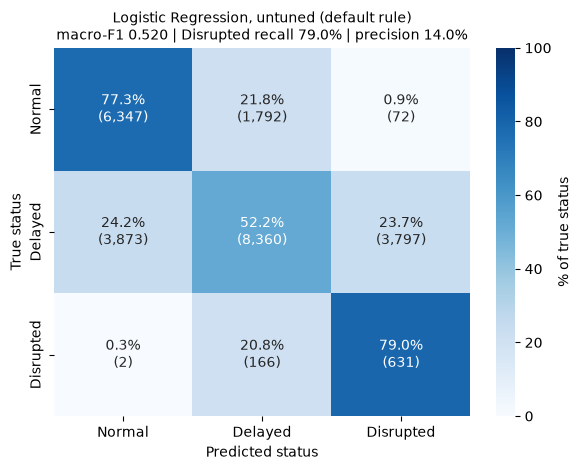

In [4]:
show_confusion_matrix("Logistic Regression", "untuned")

### Random Forest (untuned)

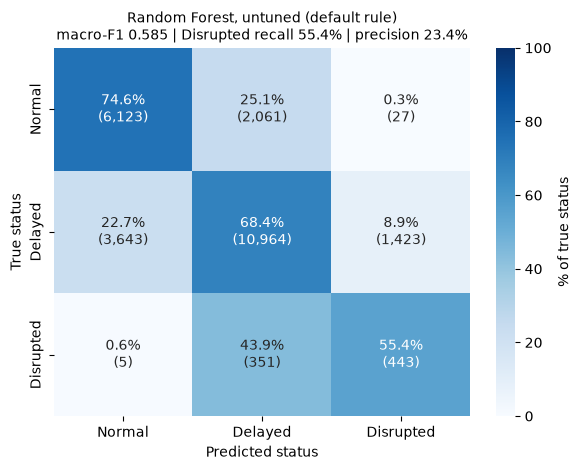

In [5]:
show_confusion_matrix("Random Forest", "untuned")

### LightGBM (untuned)

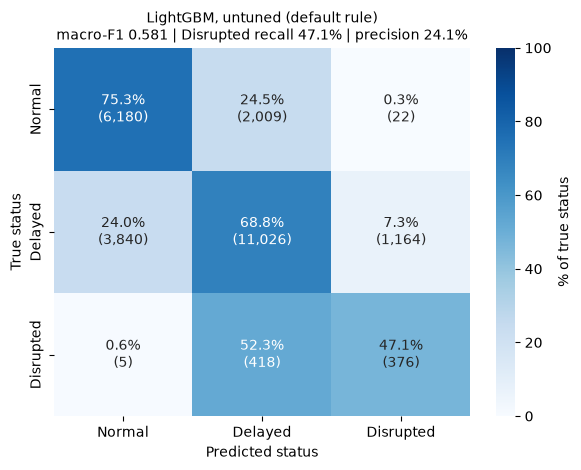

In [6]:
show_confusion_matrix("LightGBM", "untuned")

### XGBoost (untuned)

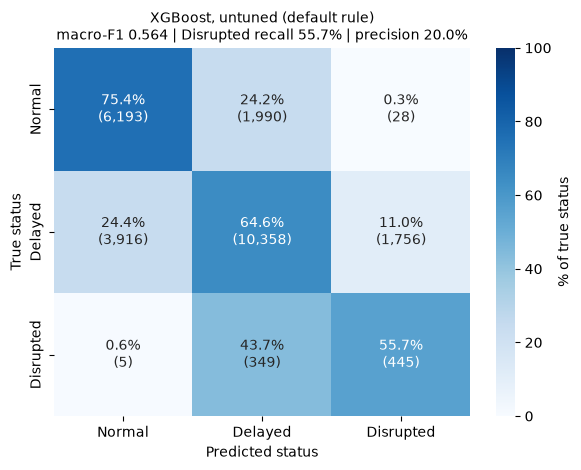

In [7]:
show_confusion_matrix("XGBoost", "untuned")

### CatBoost (untuned)

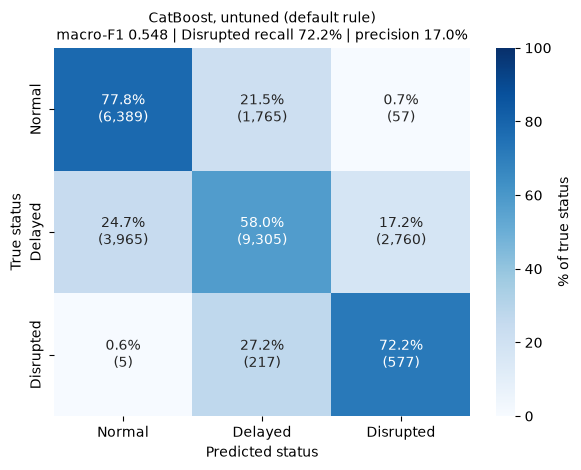

In [8]:
show_confusion_matrix("CatBoost", "untuned")

### Reading the Untuned Matrices
- **The Normal row looks almost the same for every model:** about 75-78% correct, and nearly all mistakes go to Delayed (22-25%). Almost no Normal rows are called Disrupted (0.3-0.9%).
- **The models differ mainly in how often they call Disrupted.** The class weights push every model towards Disrupted, but by different amounts:

| Model | Disrupted caught (recall) | Rows flagged Disrupted | Delayed rows flagged as Disrupted |
|---|---|---|---|
| Logistic Regression | 79.0% | 4,500 | 23.7% |
| CatBoost | 72.2% | 3,394 | 17.2% |
| XGBoost | 55.7% | 2,229 | 11.0% |
| Random Forest | 55.4% | 1,893 | 8.9% |
| LightGBM | 47.1% | 1,562 | 7.3% |

  Logistic Regression and CatBoost catch the most disruptions, but flag over 4x as many rows as there are real disruptions (799). That is why their macro-F1 looked low in 03.
- **Mistakes stay between neighboring statuses.** Missed disruptions are almost always called Delayed; at most 0.6% of real disruptions are called Normal, for every model.

## 5. Tuned Models
The same 5 models after tuning (`03_2_baseline_model_tuning_*`), each with its **own Disrupted threshold** (chosen on the other folds; the title shows the typical value).

### Logistic Regression (tuned)

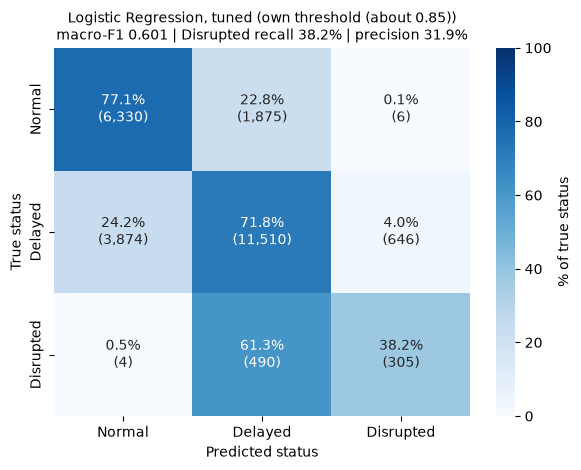

In [9]:
show_confusion_matrix("Logistic Regression", "tuned")

### Random Forest (tuned)

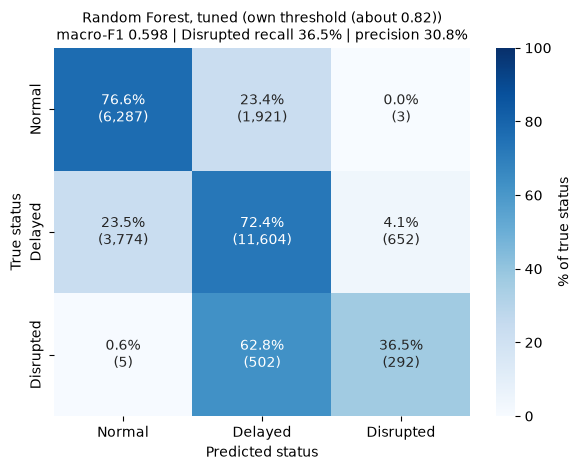

In [10]:
show_confusion_matrix("Random Forest", "tuned")

### LightGBM (tuned)

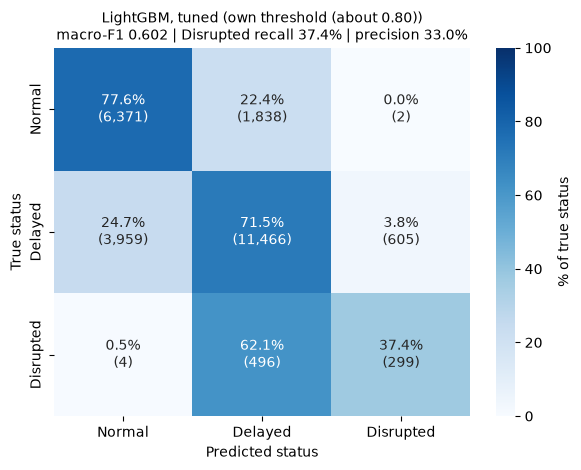

In [11]:
show_confusion_matrix("LightGBM", "tuned")

### XGBoost (tuned)

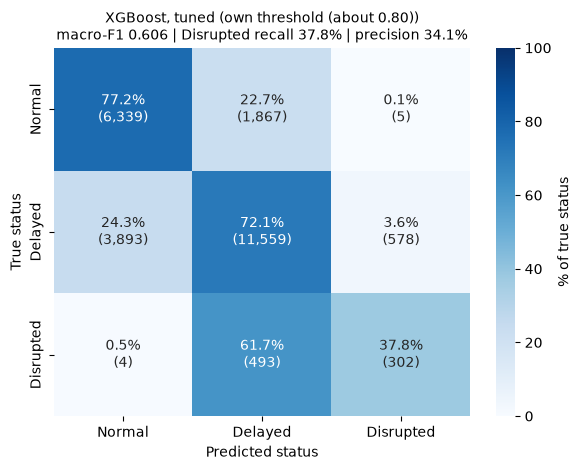

In [12]:
show_confusion_matrix("XGBoost", "tuned")

### CatBoost (tuned)

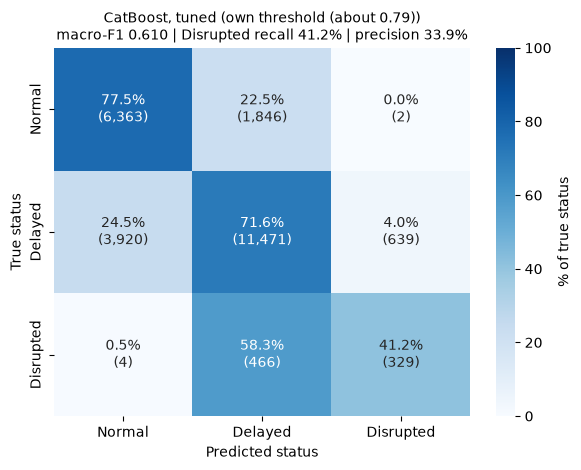

In [13]:
show_confusion_matrix("CatBoost", "tuned")

### Reading the Tuned Matrices
- **After tuning and thresholds, all 5 matrices look almost the same.** Every model catches about 37-41% of real disruptions, flags only 885-970 rows as Disrupted, and wrongly flags only about 4% of Delayed rows.
- **The tuned threshold moves rows out of the Disrupted column.** Compared with untuned, far fewer Delayed rows are flagged as Disrupted (e.g. Logistic Regression: 23.7% -> 4.0%), at the cost of catching fewer disruptions. About 1 in 3 flagged rows is now a real disruption (precision 31-34%), vs. 14-24% untuned.
- **CatBoost catches slightly more disruptions than the others** (41.2% vs. 36.5-38.2%) for a similar number of flags, which is where its small lead in macro-F1 and PR-AUC comes from.
- **The Normal vs. Delayed confusion didn't change.** About 23% of Normal rows are still called Delayed and about 24% of Delayed rows are called Normal, the same as untuned. The threshold only changes the Disrupted decision, and tuning didn't help separate Normal from Delayed.

## 6. Untuned vs. Tuned, Side by Side
The key cells of all 10 matrices in one table. Shares are of the **true** status (the matrix rows):
- `Disrupted -> Delayed`: real disruptions the model called Delayed (missed)
- `Disrupted -> Normal`: real disruptions the model called Normal (badly missed)
- `Delayed -> Disrupted`: Delayed rows flagged as Disrupted, the main source of false alarms
- `rows flagged Disrupted`: every row the model called Disrupted (there are 799 real ones)

In [14]:
summary_df = pd.DataFrame(summary_rows).set_index(["model", "version"]).sort_index(level=0, sort_remaining=False)
summary_df = summary_df.reindex([(name, version) for name in models for version in ["untuned", "tuned"]])

percent_columns = ["disrupted_recall", "disrupted_precision", "Disrupted -> Delayed", "Disrupted -> Normal",
                   "Delayed -> Disrupted", "Normal -> Delayed", "Delayed -> Normal"]
summary_df.style.format({**{c: "{:.1%}" for c in percent_columns}, "macro_f1": "{:.3f}", "rows flagged Disrupted": "{:,}"})

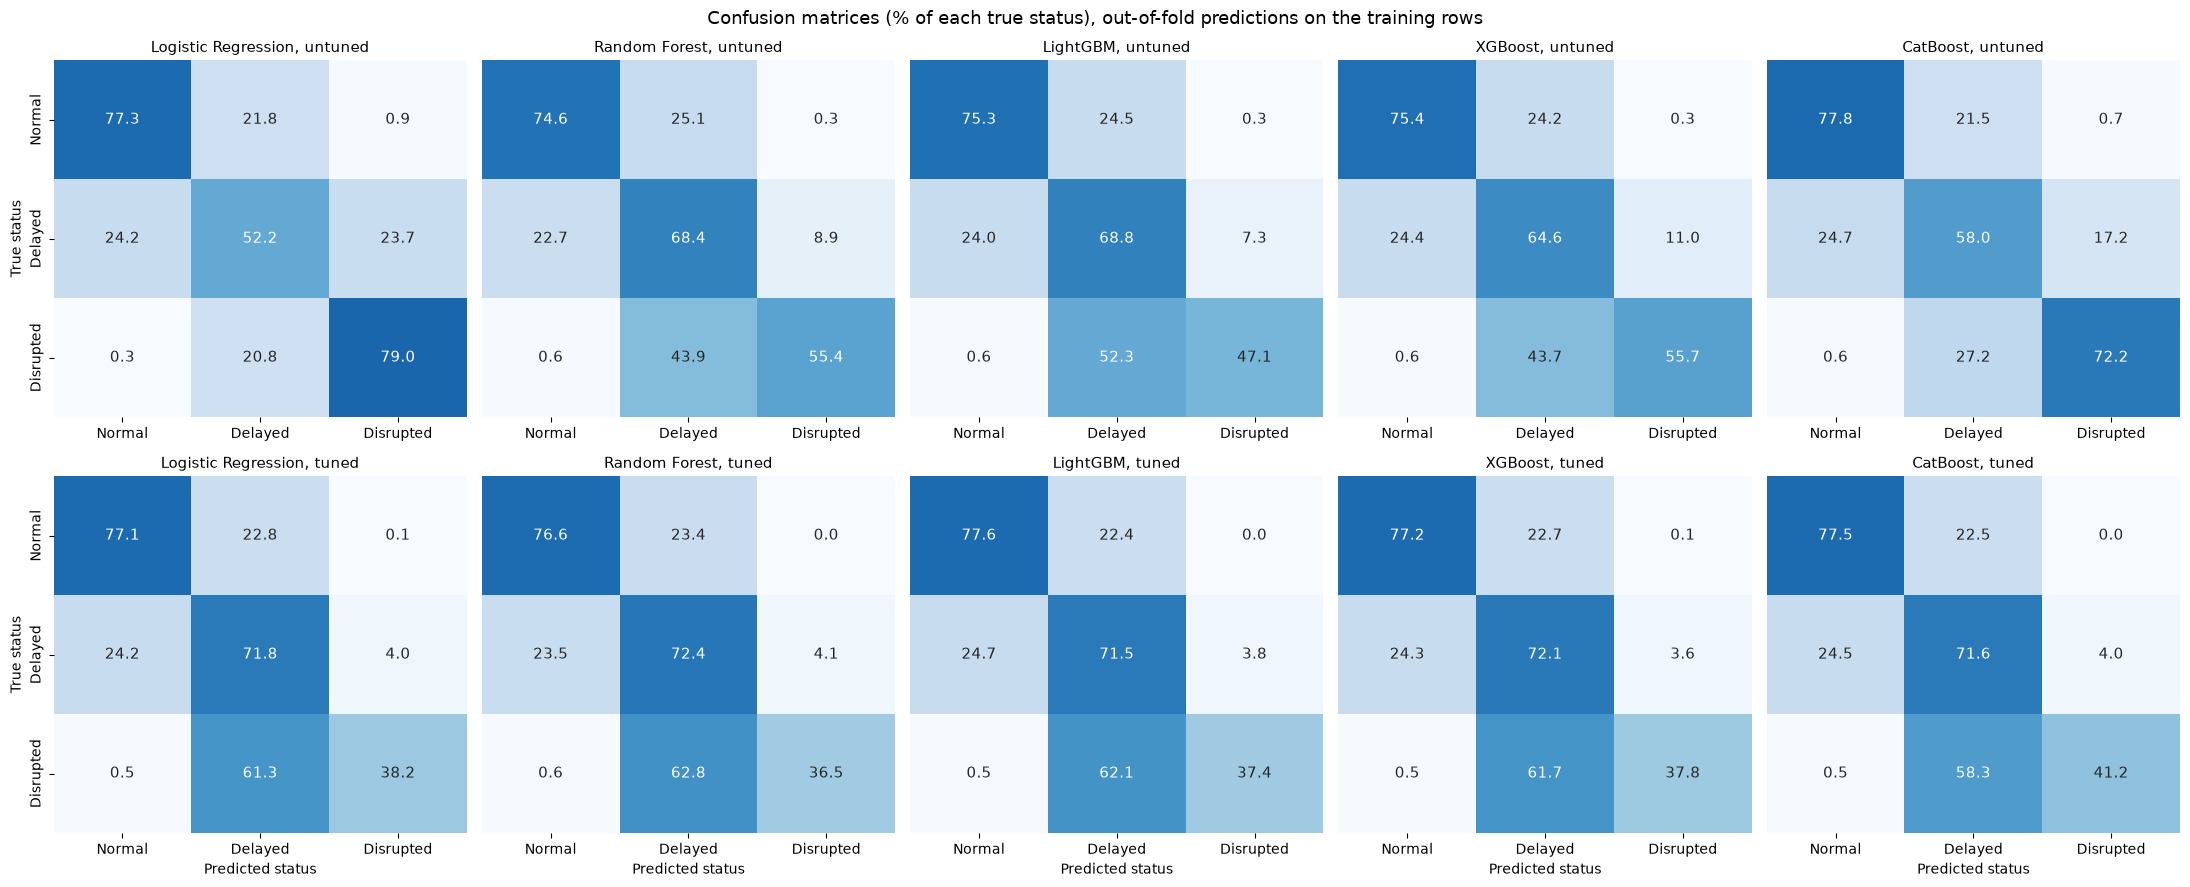

In [15]:
# All 10 matrices at a glance: untuned on top, tuned below (cells show % of the true status)
fig, axes = plt.subplots(2, 5, figsize=(22, 9))
for column, name in enumerate(models):
    for row, (version, predictions) in enumerate([("untuned", untuned_predictions), ("tuned", tuned_predictions)]):
        counts = confusion_matrix(y_train, predictions[name], labels=[0, 1, 2])
        shares = counts / counts.sum(axis=1, keepdims=True)
        ax = axes[row, column]
        sns.heatmap(shares * 100, annot=True, fmt=".1f", cmap="Blues", vmin=0, vmax=100, cbar=False,
                    xticklabels=STATUS_ORDER, yticklabels=STATUS_ORDER if column == 0 else False, ax=ax,
                    annot_kws={"fontsize": 11})
        ax.set_title(f"{name}, {version}", fontsize=11)
        ax.set_xlabel("Predicted status" if row == 1 else "")
        ax.set_ylabel("True status" if column == 0 else "")
fig.suptitle("Confusion matrices (% of each true status), out-of-fold predictions on the training rows", fontsize=13)
plt.tight_layout()
plt.show()

### Reading the Comparison
- **Tuning mostly changed *where* the models draw the Disrupted line, not *how well* they separate the statuses.** The untuned models disagreed a lot (Disrupted recall 47-79%) because each one leaned towards Disrupted by a different amount. Once each got its own threshold, they converged to nearly the same matrix.
- **False alarms dropped sharply.** For example, untuned Logistic Regression raised about 3,870 false alarms to catch 631 disruptions (about 6 per disruption caught); tuned CatBoost raises about 640 to catch 329 (about 2 per disruption caught).
- **The biggest remaining error, by number of rows, is Normal vs. Delayed:** about 3,900 Delayed rows called Normal and about 1,800-2,000 Normal rows called Delayed, for every model. Missed disruptions are a smaller count (about 470-500 rows called Delayed by the tuned models) but matter more to the business.
- **Almost no real disruption is ever called Normal** (0.3-0.6%), so even when the model misses a disruption, it nearly always still warns that the route is at least Delayed.

## 7. Summary
**What this notebook shows** (out-of-fold predictions on the 25,040 training rows; test set not used)
1. **Untuned models differ mainly in how often they call Disrupted:** from 1,562 rows (LightGBM) to 4,500 rows (Logistic Regression), for 799 real disruptions.
2. **Tuned models with their own thresholds look nearly identical:** about 37-41% of disruptions caught, about 1 in 3 alerts real, about 4% of Delayed rows wrongly flagged. CatBoost catches slightly more (41.2%).
3. **Real disruptions are almost never called Normal** (0.3-0.6%). Misses become "Delayed", so the model still signals a problem.
4. **Normal vs. Delayed is the largest remaining source of mistakes** (about a quarter of each class), and neither tuning nor the Disrupted threshold changed it.

**What this suggests for next steps**
- The Disrupted trade-off (catch more vs. fewer false alarms) is a threshold choice; see the recall-target tables in the tuning notebooks.
- Separating Normal from Delayed needs **new or better features**, not more tuning.

**Saved data used:** `results/baseline/<model>/` (from 03) and `results/tuning/<model>/` (from the 03_2 notebooks). Nothing is saved by this notebook.